# Teste 1 – Fundamentos Matemáticos
**Análise e previsão dos custos de transporte de uma empresa de e-commerce**

**Aluno:** _(coloque seu nome aqui)_

**Objetivo:** usar o conceito de função afim, f(x) = ax + b, para analisar como o custo de transporte varia ao longo de 12 meses, representar isso em gráficos e prever os custos dos próximos 3 meses.

## Etapa 1 – Carregar os dados
Vou usar a biblioteca `pandas` para ler o arquivo CSV e a `matplotlib` para fazer os gráficos.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

# Lendo o arquivo CSV
df = pd.read_csv("base_custos_transporte.csv")

# Mostrando a tabela carregada
display(df)

,mes,custo_transporte
0,1,44500
1,2,45200
2,3,48300
3,4,48600
4,5,51300
5,6,53300
6,7,53800
7,8,57000
8,9,57900
9,10,61000


## Etapa 2 – Identificar as variáveis

**a) Qual é a variável independente?**
É o **mês** (`mes`). Ela é a variável que "anda sozinha": o tempo passa independentemente do custo.

**b) Qual é a variável dependente?**
É o **custo de transporte** (`custo_transporte`). O valor do custo depende do mês em que estamos.

**c) O que cada variável representa no problema?**
- `mes`: o número do mês (de 1 a 12) em que o custo foi registrado.
- `custo_transporte`: o valor total gasto com transporte naquele mês, em reais (R$).

## Etapa 3 – Gráfico de dispersão
Colocando o mês no eixo x e o custo no eixo y.

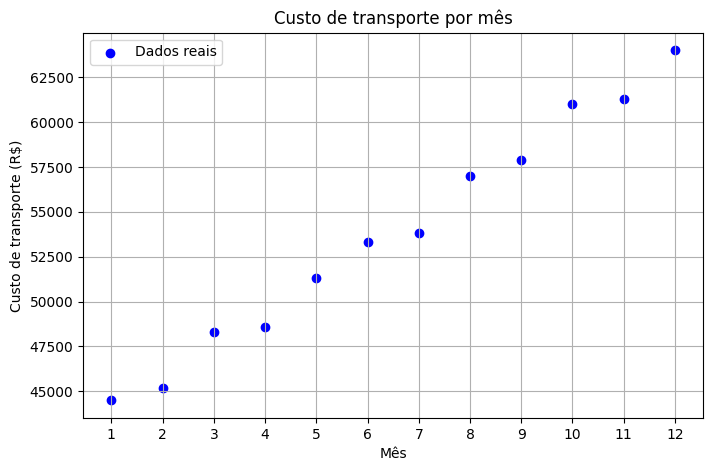

In [2]:
x = df["mes"]
y = df["custo_transporte"]

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="blue", label="Dados reais")
plt.title("Custo de transporte por mês")
plt.xlabel("Mês")
plt.ylabel("Custo de transporte (R$)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.legend()
plt.show()

**Comportamento observado:** os pontos sobem de forma quase alinhada, ou seja, o custo de transporte **aumenta mês a mês**. Começa perto de R$ 44.500 no mês 1 e chega a R$ 64.000 no mês 12. Os pontos formam quase uma linha reta, então uma função afim é uma boa escolha para representar os dados.

## Etapa 4 – Encontrar a função f(x) = ax + b

Para achar a reta que melhor se ajusta aos pontos, vou usar o **método dos mínimos quadrados**, com as fórmulas:

$$a = \frac{n \cdot \sum xy - \sum x \cdot \sum y}{n \cdot \sum x^2 - (\sum x)^2} \qquad b = \frac{\sum y - a \cdot \sum x}{n}$$

onde *n* é o número de meses. Primeiro calculo cada soma, depois aplico as fórmulas.

In [3]:
n = len(df)                 # quantidade de meses
soma_x = x.sum()            # soma dos meses
soma_y = y.sum()            # soma dos custos
soma_xy = (x * y).sum()     # soma de mes * custo
soma_x2 = (x ** 2).sum()    # soma dos meses ao quadrado

print("n =", n)
print("soma de x  =", soma_x)
print("soma de y  =", soma_y)
print("soma de xy =", soma_xy)
print("soma de x² =", soma_x2)

# Coeficiente a (inclinação da reta)
a = (n * soma_xy - soma_x * soma_y) / (n * soma_x2 - soma_x ** 2)

# Coeficiente b (valor onde a reta corta o eixo y)
b = (soma_y - a * soma_x) / n

print()
print(f"a = {a:.2f}")
print(f"b = {b:.2f}")
print(f"Função encontrada: f(x) = {a:.2f}x + {b:.2f}")

n = 12
soma de x  = 78
soma de y  = 646200
soma de xy = 4456500
soma de x² = 650

a = 1791.61
b = 42204.55
Função encontrada: f(x) = 1791.61x + 42204.55


**Resultado:**
- a ≈ **1.791,61**
- b ≈ **42.204,55**
- Função: **f(x) = 1791,61x + 42204,55**

## Etapa 5 – Interpretar a função

**a) O que representa o coeficiente a?**
É a **taxa de variação** do custo: quanto o custo muda a cada 1 mês que passa. Aqui, a ≈ 1.791,61, então o custo aumenta cerca de **R$ 1.791,61 por mês**.

**b) O que representa o coeficiente b?**
É o **valor inicial** da reta, ou seja, o custo estimado para x = 0 (um "mês 0", antes do primeiro mês). Aqui, b ≈ R$ 42.204,55. É um valor de referência do modelo, não um custo que foi realmente registrado.

**c) O valor de a indica crescimento ou redução?**
**Crescimento**, pois a é positivo (a > 0). A função é crescente.

## Etapa 6 – Gráfico dos dados com a reta
Agora vou desenhar a reta f(x) = ax + b junto com os pontos reais.

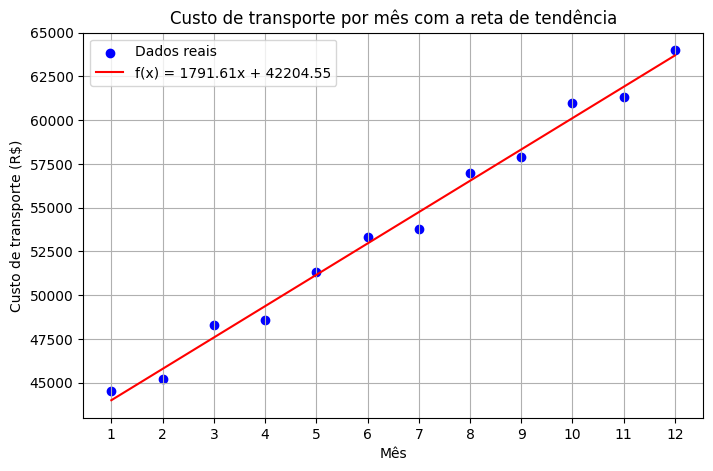

In [4]:
# Valores da reta para cada mês
y_reta = a * x + b

plt.figure(figsize=(8, 5))
plt.scatter(x, y, color="blue", label="Dados reais")
plt.plot(x, y_reta, color="red", label=f"f(x) = {a:.2f}x + {b:.2f}")
plt.title("Custo de transporte por mês com a reta de tendência")
plt.xlabel("Mês")
plt.ylabel("Custo de transporte (R$)")
plt.xticks(range(1, 13))
plt.grid(True)
plt.legend()
plt.show()

No gráfico dá para ver que a reta passa bem perto de todos os pontos e mostra a tendência de **aumento** dos custos ao longo do tempo.

## Etapa 7 – Previsões para os meses 13, 14 e 15
Basta substituir x pelo mês desejado na função f(x) = ax + b.

In [5]:
for mes in [13, 14, 15]:
    custo = a * mes + b
    print(f"Mês {mes}: f({mes}) = {a:.2f} * {mes} + {b:.2f} = R$ {custo:,.2f}")

Mês 13: f(13) = 1791.61 * 13 + 42204.55 = R$ 65,495.45
Mês 14: f(14) = 1791.61 * 14 + 42204.55 = R$ 67,287.06
Mês 15: f(15) = 1791.61 * 15 + 42204.55 = R$ 69,078.67


**Resumo das previsões (valores aproximados):**

| Mês | Cálculo | Custo estimado |
|---|---|---|
| 13 | 1791,61 · 13 + 42204,55 | R$ 65.495,45 |
| 14 | 1791,61 · 14 + 42204,55 | R$ 67.287,06 |
| 15 | 1791,61 · 15 + 42204,55 | R$ 69.078,67 |

## Etapa 8 – Analisar o resultado
Vou comparar os valores previstos pela função com os valores reais dos últimos meses.

In [6]:
comparacao = df.copy()
comparacao["custo_previsto"] = (a * comparacao["mes"] + b).round(2)
comparacao["erro"] = (comparacao["custo_transporte"] - comparacao["custo_previsto"]).round(2)

# Últimos 4 meses
display(comparacao.tail(4))

# Erro médio (sem considerar o sinal)
erro_medio = comparacao["erro"].abs().mean()
print(f"Erro médio absoluto: R$ {erro_medio:.2f}")

# Diferença média mensal observada nos dados reais
aumento_medio = (y.iloc[-1] - y.iloc[0]) / (len(y) - 1)
print(f"Aumento médio mensal real: R$ {aumento_medio:.2f}")

Erro médio absoluto: R$ 557.63
Aumento médio mensal real: R$ 1772.73


,mes,custo_transporte,custo_previsto,erro
8,9,57900,58329.02,-429.02
9,10,61000,60120.63,879.37
10,11,61300,61912.24,-612.24
11,12,64000,63703.85,296.15


**a) A função representa bem a tendência dos dados?**
Sim. Nos últimos meses, os valores previstos ficam muito perto dos reais (a diferença fica em torno de algumas centenas de reais, com erro médio de aproximadamente R$ 558), o que é pouco perto de custos na faixa de R$ 60 mil. Os pontos ficam quase todos em cima da reta.

**b) Os custos estão aumentando ou diminuindo?**
Estão **aumentando**: passaram de R$ 44.500 (mês 1) para R$ 64.000 (mês 12).

**c) Quanto o custo aumenta por mês, aproximadamente?**
Cerca de **R$ 1.800 por mês** (o valor de a é R$ 1.791,61). Calculando direto pelos dados reais, (64.000 − 44.500) ÷ 11 ≈ R$ 1.772,73, que é bem próximo.

## Etapa 9 – Conclusão

Os dados dos 12 meses mostram que o custo de transporte da empresa **cresce de forma quase linear**, aumentando em média R$ 1.800 por mês. A função afim f(x) = 1791,61x + 42204,55 se ajustou bem aos dados e serviu para fazer previsões.

Com base nisso, a empresa pode esperar que os custos **continuem subindo** nos próximos meses, chegando a aproximadamente **R$ 65.495** no mês 13, **R$ 67.287** no mês 14 e **R$ 69.079** no mês 15.

**Observação importante:** essa previsão supõe que o comportamento dos últimos 12 meses continue igual. Se houver mudanças (aumento de combustível, novas rotas, mudança de transportadora, épocas de mais vendas etc.), os valores reais podem ser diferentes. Por isso, a empresa deve pensar em ajustar o orçamento de transporte e buscar formas de reduzir custos.